In [1]:
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError("Cannot find the dataset folder.")

DATASET_PATH = PROJECT_ROOT / "dataset"
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Project:", PROJECT_ROOT)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", CLASS_NAMES)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Project: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI
Image size: (224, 224)
Batch size: 16
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
GPU devices: []


In [3]:

def load_split(split_name, shuffle):
    split_path = DATASET_PATH / split_name

    if not split_path.is_dir():
        raise FileNotFoundError(f"Missing folder: {split_path}")

    return tf.keras.utils.image_dataset_from_directory(
        split_path,
        labels="inferred",
        label_mode="int",
        class_names=CLASS_NAMES,
        color_mode="rgb",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    )


train_raw = load_split("train", shuffle=True)
valid_raw = load_split("valid", shuffle=False)
test_raw = load_split("test", shuffle=False)

print("\nClass order:", train_raw.class_names)
print("Training batches:", tf.data.experimental.cardinality(train_raw).numpy())
print("Validation batches:", tf.data.experimental.cardinality(valid_raw).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_raw).numpy())


Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Found 246 files belonging to 4 classes.

Class order: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Training batches: 106
Validation batches: 32
Test batches: 16


In [4]:

augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.04),
        tf.keras.layers.RandomZoom(0.05),
    ],
    name="training_augmentation"
)


def preprocess_train(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    images = augmentation(images, training=True)
    return images, labels


def preprocess_eval(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels


AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    train_raw
    .map(preprocess_train, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

valid_ds = (
    valid_raw
    .map(preprocess_eval, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_raw
    .map(preprocess_eval, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


In [5]:

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))
print("Image tensor dtype:", images.dtype)
print("Label tensor dtype:", labels.dtype)

assert images.shape[1:] == (224, 224, 3)
assert labels.shape[0] == images.shape[0]
assert float(tf.reduce_min(images)) >= 0.0
assert float(tf.reduce_max(images)) <= 1.0

print("\nAll preprocessing checks passed.")


Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Image tensor dtype: <dtype: 'float32'>
Label tensor dtype: <dtype: 'int32'>

All preprocessing checks passed.


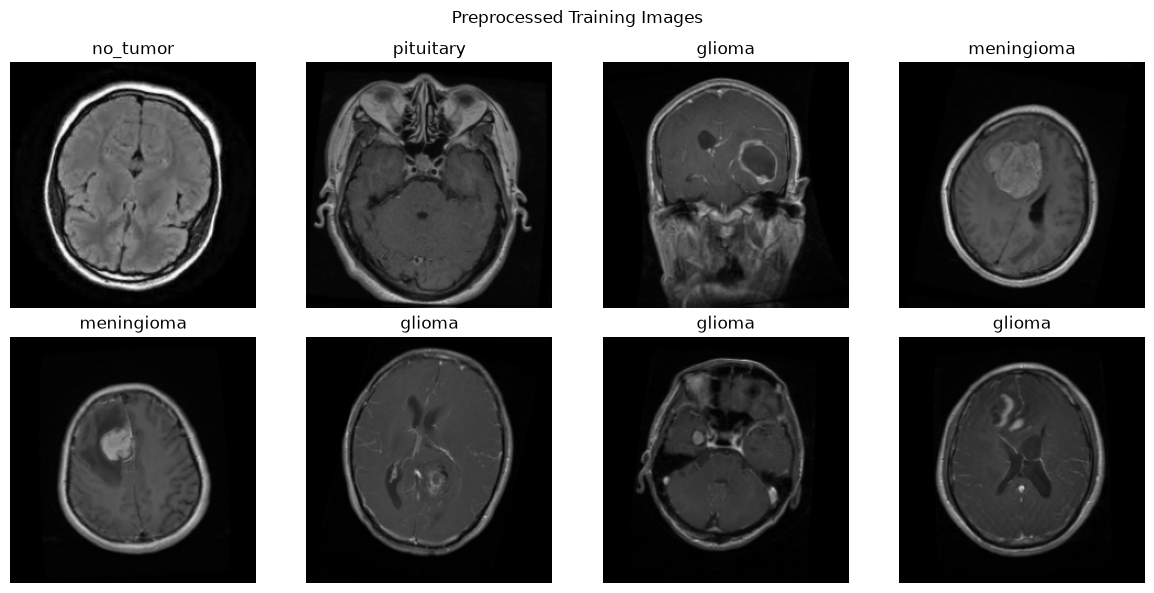

Saved: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\reports\figures\preprocessed_samples.png


In [6]:

images, labels = next(iter(train_ds))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    if i >= len(images):
        ax.axis("off")
        continue

    ax.imshow(images[i].numpy())
    ax.set_title(CLASS_NAMES[int(labels[i].numpy())])
    ax.axis("off")

fig.suptitle("Preprocessed Training Images")
fig.tight_layout()

output_path = REPORTS_DIR / "figures" / "preprocessed_samples.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(output_path, dpi=120, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


In [7]:

class_mapping = {
    str(index): class_name
    for index, class_name in enumerate(CLASS_NAMES)
}

mapping_path = REPORTS_DIR / "class_mapping.json"

with open(mapping_path, "w", encoding="utf-8") as file:
    json.dump(class_mapping, file, indent=2)

print(json.dumps(class_mapping, indent=2))
print("Saved:", mapping_path)


{
  "0": "glioma",
  "1": "meningioma",
  "2": "no_tumor",
  "3": "pituitary"
}
Saved: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\reports\class_mapping.json
